# CC2017 – Deep Learning · Proyecto Final
## 05 · Evaluación comparativa en el test oficial

Se cargan los checkpoints de los notebooks 02 y 03 y se evalúan sobre las 12,630 imágenes del test oficial de GTSRB, que ningún modelo vio durante el entrenamiento ni la selección de hiperparámetros.

## Preparación · Librerías, reproducibilidad y dispositivo

In [1]:
import sys, random, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
OUT = ROOT / 'outputs'; OUT.mkdir(exist_ok=True)

# FAST_DEV_RUN=True recorre pocos lotes por época para comprobar que todo corre; sus checkpoints llevan prefijo dev_.
FAST_DEV_RUN = False
MAX_BATCHES = 5 if FAST_DEV_RUN else None
PREFIX = 'dev_' if FAST_DEV_RUN else ''
NUM_WORKERS = 2
print('Dispositivo:', device, '| FAST_DEV_RUN:', FAST_DEV_RUN)

Dispositivo: cpu | FAST_DEV_RUN: False


## 1. Datos y modelos

In [2]:
from src.data import download_gtsrb, load_tables, split_train_val, GTSRBDataset, get_transforms, CLASS_NAMES, NUM_CLASSES

DATA_ROOT = download_gtsrb()
train_full, test_df = load_tables(DATA_ROOT)
train_df, val_df = split_train_val(train_full, val_size=0.15, seed=SEED)
print(f'Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')

c:\Users\mdax8\Desktop\UVG\8 Semestre\Deep Learning\Proyecto Final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 33,299 | Val: 5,910 | Test: 12,630


In [3]:
from src.models import TrafficCNN, build_mobilenet_v2

def test_loader(size, imagenet_norm):
    ds = GTSRBDataset(test_df, DATA_ROOT, get_transforms(size, imagenet_norm=imagenet_norm))
    return DataLoader(ds, 128, num_workers=NUM_WORKERS)

def load(model, name):
    ckpt = torch.load(OUT / f'{PREFIX}{name}.pt', map_location=device, weights_only=False)
    model.load_state_dict(ckpt['model']); return model.to(device).eval()

candidates = [
    ('CNN desde cero', lambda: TrafficCNN(), 'cnn_scratch', 48, False),
    ('MobileNetV2 congelado', lambda: build_mobilenet_v2(pretrained=False), 'mobilenet_frozen', 96, True),
    ('MobileNetV2 fine-tuning', lambda: build_mobilenet_v2(pretrained=False), 'mobilenet_finetuned', 96, True),
]
models_eval = [(name, load(make(), ck), size, norm) for name, make, ck, size, norm in candidates
               if (OUT / f'{PREFIX}{ck}.pt').exists()]
print('Modelos encontrados:', [m[0] for m in models_eval])

Modelos encontrados: ['CNN desde cero', 'MobileNetV2 congelado', 'MobileNetV2 fine-tuning']


## 2. Métricas globales
Accuracy, precision, recall y F1. El promedio **macro** da el mismo peso a cada clase, así que penaliza fallar en las clases con pocos ejemplos. El **weighted** pondera por la cantidad de ejemplos de cada clase.

In [4]:
from src.metrics import predict, summary_metrics, plot_confusion, top_confusions
preds, rows = {}, []
for name, model, size, norm in models_eval:
    loader = test_loader(size, norm)
    t0 = time.time()
    y, p, prob = predict(model, loader, device, MAX_BATCHES)
    preds[name] = (y, p, prob)
    rows.append({**summary_metrics(y, p, name), 'ms_por_imagen': 1000 * (time.time() - t0) / len(y)})
results = pd.DataFrame(rows).round(4)
results.to_csv(OUT / f'{PREFIX}metricas_test.csv', index=False)
results

,modelo,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,ms_por_imagen
0,CNN desde cero,0.9918,0.9856,0.9893,0.9870,0.9922,0.9918,0.9919,7.4094
1,MobileNetV2 congelado,0.5991,0.5539,0.5083,0.5164,0.6077,0.5991,0.5962,3.0929
2,MobileNetV2 fine-tuning,0.7676,0.7464,0.7040,0.7102,0.7894,0.7676,0.7668,3.6177


## 3. Matrices de confusión
Matrices normalizadas por fila: la diagonal es el recall de cada clase. Las celdas fuera de la diagonal muestran con qué clase se confunde cada una.

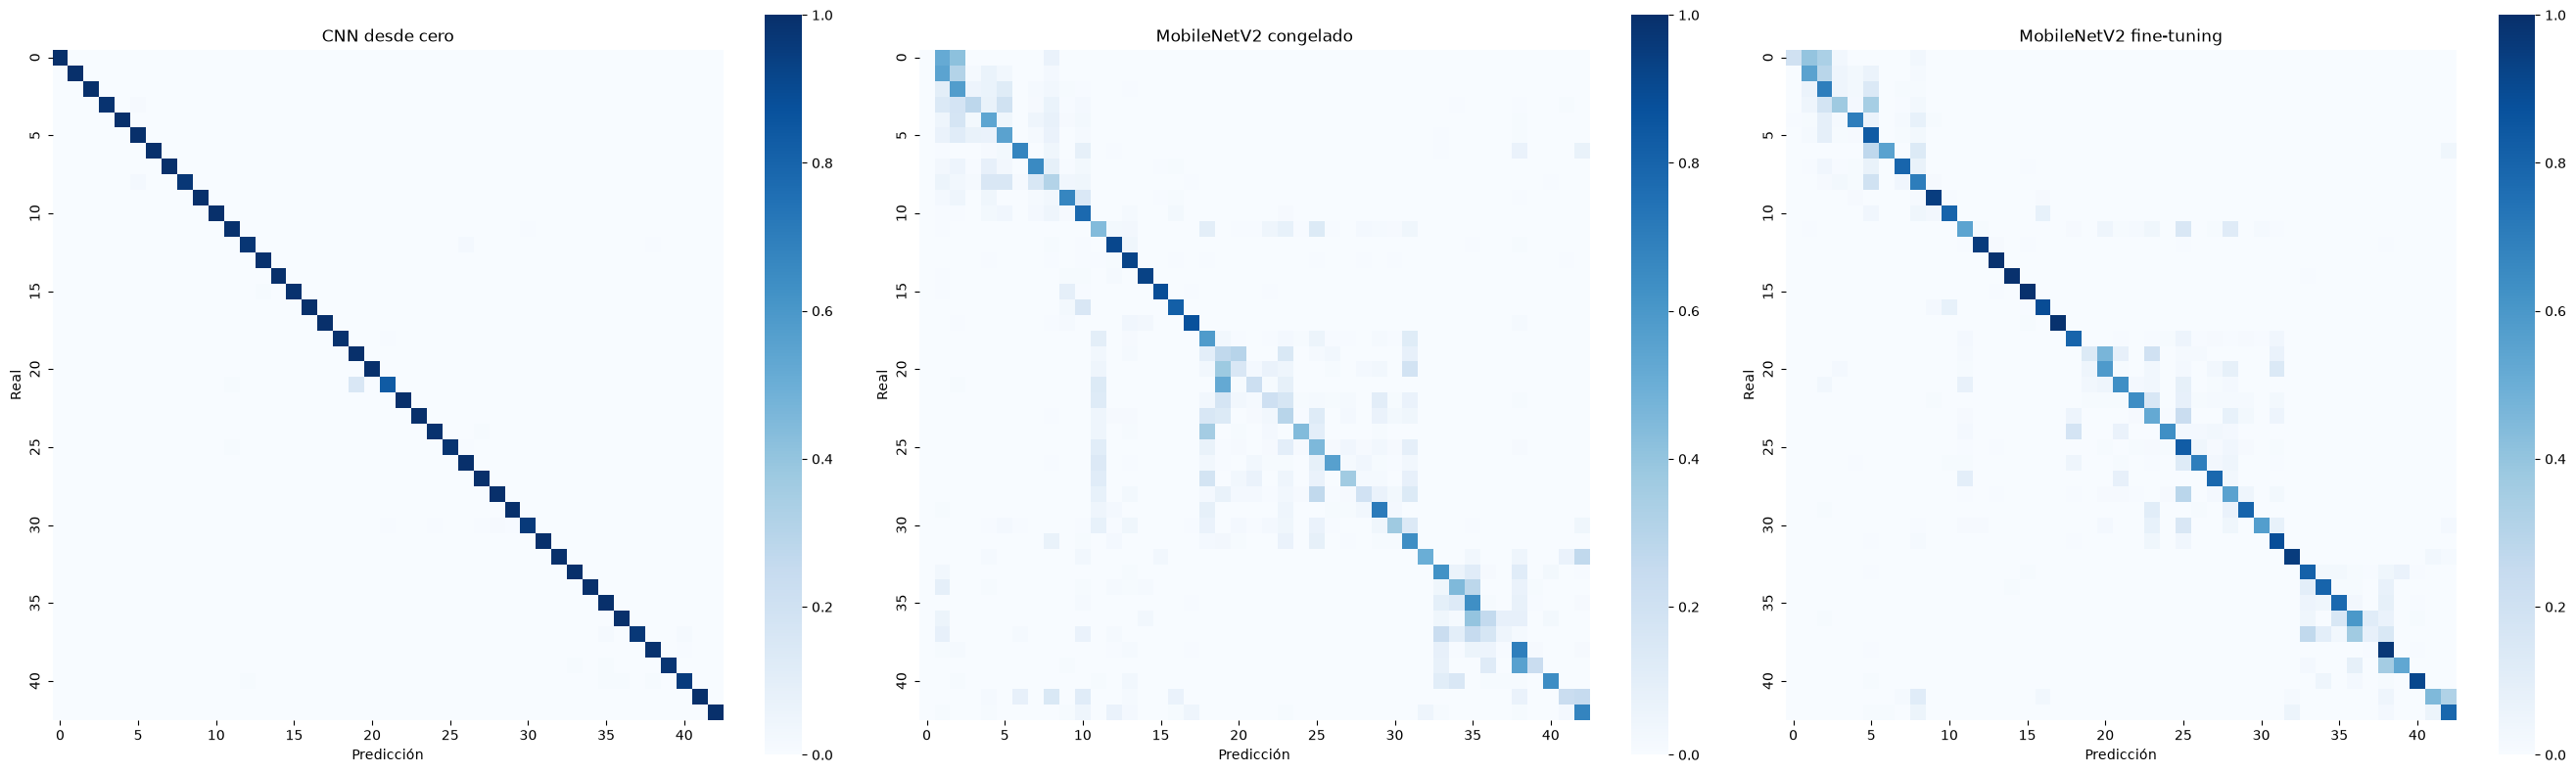

In [5]:
fig, axs = plt.subplots(1, len(preds), figsize=(9 * len(preds), 8))
axs = np.atleast_1d(axs)
for ax, (name, (y, p, _)) in zip(axs, preds.items()):
    plot_confusion(y, p, NUM_CLASSES, title=name, ax=ax)
plt.tight_layout(); plt.savefig(OUT / 'confusion_test.png', dpi=120); plt.show()

## 4. Confusiones más frecuentes

In [6]:
for name, (y, p, _) in preds.items():
    print(name); display(top_confusions(y, p, CLASS_NAMES, k=8))

CNN desde cero


,real,predicho,errores
0,Curva doble,Curva peligrosa a la izquierda,14
1,Vía con prioridad,Semáforo,14
2,Límite 120 km/h,Límite 80 km/h,9
3,Límite 60 km/h,Límite 80 km/h,6
4,Mantenerse a la derecha,Glorieta obligatoria,5
5,Obras,Prioridad en próxima intersección,4
6,Obras,Semáforo,3
7,Vía con prioridad,Mantenerse a la derecha,3


MobileNetV2 congelado


,real,predicho,errores
0,Límite 30 km/h,Límite 50 km/h,223
1,Límite 70 km/h,Límite 50 km/h,115
2,Límite 60 km/h,Límite 80 km/h,89
3,Límite 50 km/h,Límite 80 km/h,89
4,Límite 60 km/h,Límite 50 km/h,80
5,Límite 50 km/h,Límite 30 km/h,79
6,Límite 80 km/h,Límite 50 km/h,72
7,Límite 120 km/h,Límite 100 km/h,72


MobileNetV2 fine-tuning


,real,predicho,errores
0,Límite 30 km/h,Límite 50 km/h,209
1,Límite 60 km/h,Límite 80 km/h,157
2,Límite 50 km/h,Límite 80 km/h,108
3,Límite 120 km/h,Límite 80 km/h,88
4,Límite 60 km/h,Límite 50 km/h,81
5,Prioridad en próxima intersección,Obras,64
6,Límite 70 km/h,Límite 50 km/h,61
7,Límite 80 km/h,Límite 50 km/h,57


## 5. F1 por clase

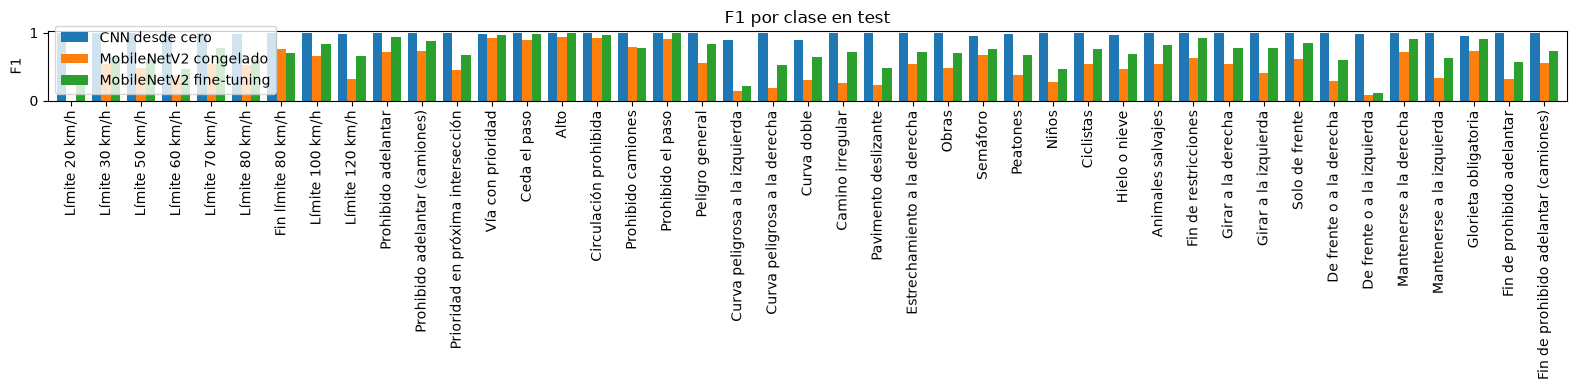

,F1 mínimo entre modelos
Límite 20 km/h,0.000000
De frente o a la izquierda,0.076923
Curva peligrosa a la izquierda,0.135021
Curva peligrosa a la derecha,0.181818
Pavimento deslizante,0.234667
Camino irregular,0.252525
Niños,0.272300
De frente o a la derecha,0.287037
Curva doble,0.300752
Límite 120 km/h,0.314254


In [7]:
from sklearn.metrics import f1_score
f1_cls = pd.DataFrame({name: f1_score(y, p, average=None, labels=range(NUM_CLASSES), zero_division=0)
                       for name, (y, p, _) in preds.items()}, index=CLASS_NAMES)
ax = f1_cls.plot.bar(figsize=(16, 4), width=.8); ax.set(ylabel='F1', ylim=(0, 1.02), title='F1 por clase en test')
plt.tight_layout(); plt.savefig(OUT / 'f1_por_clase.png', dpi=120); plt.show()
f1_cls.min(axis=1).sort_values().head(10).to_frame('F1 mínimo entre modelos')

**Interpretación.** La CNN desde cero obtiene el mejor resultado: 0.9918 de accuracy y 0.9870 de F1 macro. Supera a MobileNetV2 con fine-tuning por 22.42 puntos porcentuales de accuracy y a la versión congelada por 39.27. La cercanía entre F1 macro y weighted en la CNN indica un desempeño equilibrado entre clases frecuentes y minoritarias. MobileNetV2 presenta una brecha mayor y concentra errores en límites de velocidad visualmente similares. La CNN tarda 7.41 ms por imagen en CPU, frente a 3.09 ms del modelo congelado y 3.62 ms del ajustado; se elige la CNN porque la ganancia de exactitud compensa esta diferencia de pocos milisegundos.